In [21]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')


ivan.uio.no


In [72]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, set_context, pearsonr, IMProToo, pd)
# from matplotlib.collections import PathCollection
import functions as fct


In [23]:
version = IMProToo.__version__

In [24]:
# plot cosmetics
set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )

In [25]:
# reload imports
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
site = 'ANX'
year = '2023'

In [ ]:
df = dict()
vars_to_keep = ['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'snowflake_class_name', 'rate_mm_h', 
                'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400',
                'Matrosov_a_400_mm_h', 'Bracci_a_400_mm_h', 'Nakai_a_400_mm_h', 'Nakai_g_400_mm_h', 'Pu_g_400_mm_h', 'start_time', 'Ze_400m', 'S_a_b_400m']

open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc'))))
df['event_offset'] = open_ds[vars_to_keep].to_dataframe()



for dt in ['1min', '5min', '10min', '30min', '60min']:
    open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_{dt}_dt_offset_{site}_{year}.nc'))))
    df[dt] = open_ds[vars_to_keep].to_dataframe()


 
    

### Filter the dominant snowflake class and create individual dataframes

In [ ]:
aggregate = {}
graupel = {}
mixed = {}
pristine = {}
sf_class_dict = {}
for dt in ['event_offset', ]:#'1min', '5min', '10min', '30min', '60min']:
    aggregate[dt]   = df[dt][df[dt]['snowflake_class_name'] == 'aggregate']
    graupel[dt]     = df[dt][df[dt]['snowflake_class_name'] == 'graupel']
    mixed[dt]       = df[dt][df[dt]['snowflake_class_name'] == 'mixed']
    pristine[dt]    = df[dt][df[dt]['snowflake_class_name'] == 'pristine']

    sf_class_dict[dt] = {'aggregate':aggregate[dt], 'graupel':graupel[dt], 'mixed':mixed[dt], 'pristine':pristine[dt]}

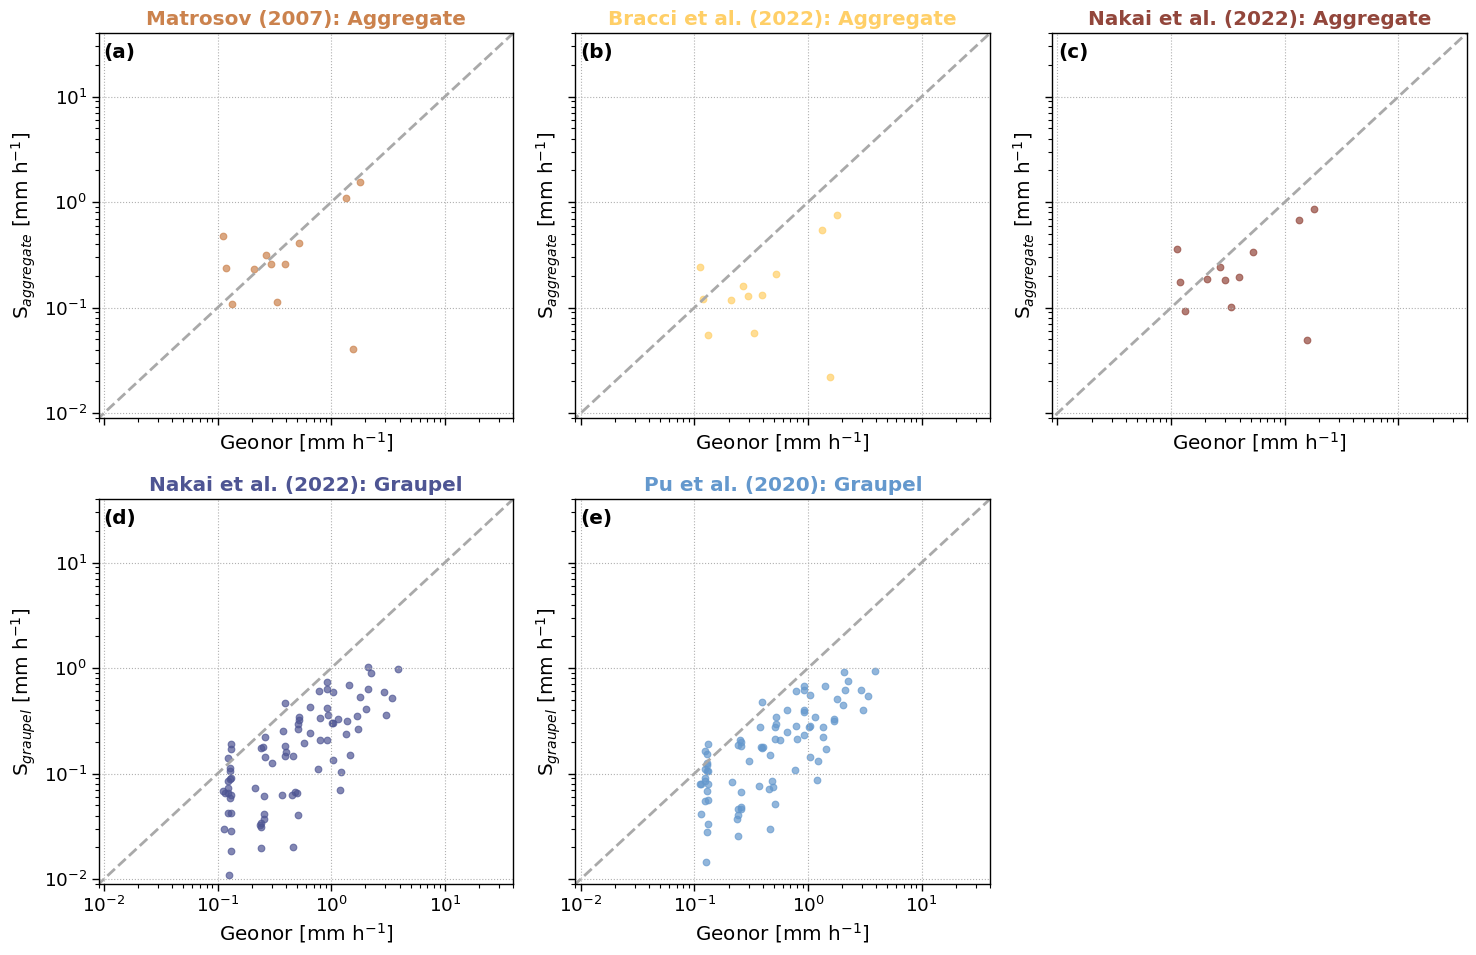

In [29]:
fct.plt_precip_scatter_literature(sf_class_dict[dt], title="")

In [30]:
# xval =sf_class_dict[dt]['graupel']['rate_mm_h']
# name = 'Matrosov_a'
# yval =sf_class_dict[dt]['graupel'][f'{name}_400_mm_h']

dt = 'event_offset'
xval =df[dt]['rate_mm_h']
name = 'Matrosov_a'
yval =df[dt][f'{name}_400_mm_h']

In [31]:
# some sanity-checks
print("N points:", len(xval))
print("Any NaNs:", np.isnan(np.log10(xval)).any(), np.isnan(np.log10(yval)).any())
print("Any infs:", np.isinf(np.log10(xval)).any(), np.isinf(np.log10(yval)).any())

N points: 607
Any NaNs: False True
Any infs: False False


In [32]:
mask = (
    (xval > 0) & 
    (yval > 0) &
    np.isfinite(xval) &
    np.isfinite(yval)
)
xval = xval[mask]
yval = yval[mask]

In [33]:
# Transform the data to logarithmic scales
log_x = np.log10(xval)
log_y = np.log10(yval)

In [34]:
# some sanity-checks
print("N points:", len(xval))
print("Any NaNs:", np.isnan(np.log10(xval)).any(), np.isnan(np.log10(yval)).any())
print("Any infs:", np.isinf(np.log10(xval)).any(), np.isinf(np.log10(yval)).any())

N points: 539
Any NaNs: False False
Any infs: False False


In [35]:
# Fit a straight line (y=mx+b) to the log-transformed data
# np.polyfit returns the slope (m) and the intercept (b or log(k))
m_fit, log_k_fit = np.polyfit(log_x, log_y, 1)

k_fit = 10**log_k_fit

In [36]:
# R^2 in log space
log_y_pred = m_fit * log_x + log_k_fit

ss_res = np.sum((log_y - log_y_pred)**2)
ss_tot = np.sum((log_y - np.mean(log_y))**2)

r2 = 1 - ss_res / ss_tot
r2

np.float64(0.2550973661702557)

In [37]:
# Pearson r and p-values
r, p = pearsonr(log_x, log_y)

In [38]:
r,p

(np.float64(0.5050716445913941), np.float64(3.088831626080401e-36))

Fitted exponent (n): 0.6840
Fitted constant (k): 0.5814
The power law equation is approximately Y = 0.5814 * X^0.6840
The R^2 is approximately 0.2551


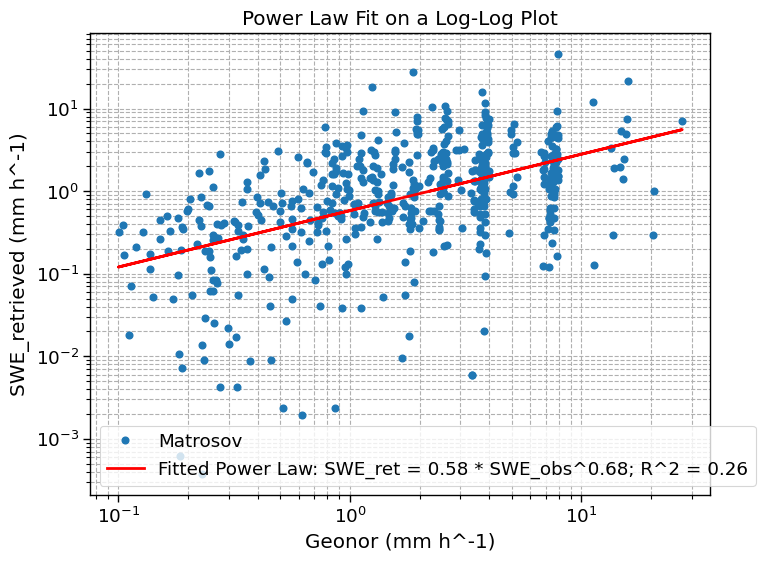

In [39]:
# 5. Print the results
print(f"Fitted exponent (n): {m_fit:.4f}")
print(f"Fitted constant (k): {k_fit:.4f}")
print(f"The power law equation is approximately Y = {k_fit:.4f} * X^{m_fit:.4f}")
print(f"The R^2 is approximately {r2:.4f}")

# 6. Plot the results on a log-log scale
plt.figure(figsize=(8, 6))
plt.loglog(xval, yval, 'o', label='Matrosov') # Use plt.loglog for log axes
plt.plot(xval, k_fit * xval**m_fit, '-', color='red', label=f'Fitted Power Law: SWE_ret = {k_fit:.2f} * SWE_obs^{m_fit:.2f}; R^2 = {r2:.2f}')
plt.xlabel('Geonor (mm h^-1)')
plt.ylabel('SWE_retrieved (mm h^-1)')
plt.title('Power Law Fit on a Log-Log Plot')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

In [80]:
file_pattern = f"{INPUT_DATA_DIR}/MRR_ANX/maahn/mrr_improtoo_{version}_{site}_*2023*.nc"
file_list = sorted(glob(file_pattern))

out_dir = pathlib.Path(OUTPUT_DATA_DIR, 'MRR_ANX', 'maahn')

In [86]:
ds_corrected = xr.open_dataset(file_list[0])

ds_corrected = ds_corrected.drop_vars(['Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel'])

In [87]:
ze = fct.noise_corrected_ze(ds['Ze'])

In [92]:
def ze_to_snowfall_rate_ensemble(Ze_dbz, a, b):
    Ze_lin = 10 ** (Ze_dbz/10)
    # Apply Z-S relationship
    S = (Ze_lin / a ) ** (1/b)

    # convert rate per minute to mm/h
    S = (S/60)

    da1 = S.rename(f'S_{a}_{b}')

    return da1

In [93]:
a = 50; b = 1.
da_snowfall_rate = ze_to_snowfall_rate_ensemble(ze, a, b)


In [ ]:
ds_corrected = xr.merge([ds_corrected, da_snowfall_rate])

ds_corrected[f'S_{a}_{b}'] = ds_corrected[f'S_{a}_{b}'].assign_attrs(units = "mm/h", description = "Snowfall using predifined a and b in Z=a*S^b")

<xarray.Dataset> Size: 76MB
Dimensions:                  (time: 775, range: 31, velocity: 192,
                              velocity_noDA: 64)
Coordinates:
  * time                     (time) datetime64[ns] 6kB 2023-02-12T11:06:00 .....
  * range                    (range) float64 248B 1.0 2.0 3.0 ... 29.0 30.0 31.0
  * velocity                 (velocity) float32 768B -12.12 -11.93 ... 24.05
  * velocity_noDA            (velocity_noDA) float32 256B 0.0 0.1894 ... 11.93
Data variables: (12/29)
    height                   (time, range) float32 96kB ...
    eta_noDA                 (time, range, velocity_noDA) float32 6MB ...
    etaMask_noDA             (time, range, velocity_noDA) float64 12MB ...
    eta                      (time, range, velocity) float32 18MB ...
    etaMask                  (time, range, velocity) float64 37MB ...
    quality                  (time, range) float64 192kB ...
    ...                       ...
    W_noDA                   (time, range) float32 96kB ...
    W                        (time, range) float32 96kB ...
    etaNoiseAve              (time, range) float32 96kB ...
    etaNoiseStd              (time, range) float32 96kB ...
    SNR                      (time, range) float32 96kB ...
    S_50_1.0                 (time, range) float32 96kB nan nan nan ... nan nan
Attributes:
    title:            Micro rain radar data processed with IMProToo
    comment:          IMProToo has been developed for improved snow measureme...
    institution:      Dept. of Geoscience, University of Oslo
    contact_person:   F. Hellmuth
    source:           MRR-2
    location:         Andenes
    history:          Created with IMProToo v0.107
    author:           Max Maahn
    processing_date:  2025-08-28 11:19:35 UTC
    reference:        Maahn, M. and Kollias, P., 2012: Improved Micro Rain Ra...
    properties:       {'debug': 0, 'mrrFrequency': 24150000000.0, 'lamb': 0.0...
    mrrHeader:        MRR 230212110540 UTC DVS 6.10 DSN 200607002 BW 32700 CC...

In [73]:
pd.concat([df1, df1], axis=1)

S_50_1.0  S_50_1.0
time                range                    
2023-02-12 11:06:00 1.0         NaN       NaN
                    2.0         NaN       NaN
                    3.0         NaN       NaN
                    4.0         NaN       NaN
                    5.0         NaN       NaN
...                             ...       ...
2023-02-13 00:00:00 27.0        NaN       NaN
                    28.0        NaN       NaN
                    29.0        NaN       NaN
                    30.0        NaN       NaN
                    31.0        NaN       NaN

[24025 rows x 2 columns]